# 02 Energía de España

Este dataset es un recopilatorio de datos del mercado eléctrico de España.  
Contiene 6 columnas: `datetime`, `id`, `name`, `geoid`, `geoname` y `value`.  
Preguntas del dataset:
* ¿Qué periodo cubre?
* ¿Cuántas filas tiene?
* ¿Mide solo casas, o qué mide?  
Preguntas:
* ¿Cuándo es más barata la electricidad?
* ¿El consumo cambia conforme cambian las estaciones?
* ¿El consumo cambia dependiendo de la hora del día?

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## 1. Exploración

In [2]:
df = pd.read_csv("spain_energy_market.csv")
df.head()

,datetime,id,name,geoid,geoname,value
0,2014-01-01 23:00:00,600,Precio mercado SPOT Diario ESP,3.0,España,25.280833
1,2014-01-02 23:00:00,600,Precio mercado SPOT Diario ESP,3.0,España,39.924167
2,2014-01-03 23:00:00,600,Precio mercado SPOT Diario ESP,3.0,España,4.992083
3,2014-01-04 23:00:00,600,Precio mercado SPOT Diario ESP,3.0,España,4.091667
4,2014-01-05 23:00:00,600,Precio mercado SPOT Diario ESP,3.0,España,13.587500


In [3]:
df.shape

(40212, 6)

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 40212 entries, 0 to 40211
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   datetime  40212 non-null  str    
 1   id        40212 non-null  int64  
 2   name      34734 non-null  str    
 3   geoid     10956 non-null  float64
 4   geoname   10956 non-null  str    
 5   value     40212 non-null  float64
dtypes: float64(2), int64(1), str(3)
memory usage: 1.8 MB


In [5]:
df['name'].value_counts()

name
Precio mercado SPOT Diario ESP                                            1826
Precio mercado SPOT Diario FRA                                            1826
Precio mercado SPOT Diario POR                                            1826
Energía asignada en Mercado SPOT Diario España                            1826
Energía asignada en Mercado SPOT Diario Francia                           1826
Generación programada PBF Gas Natural Cogeneración                        1826
Generación programada PBF UGH + no UGH                                    1826
Generación programada PBF Solar fotovoltaica                              1826
Demanda real                                                              1825
Demanda programada PBF total                                              1825
Generación programada PBF total                                           1825
Generación programada PBF Eólica                                          1825
Generación programada PBF Nuclear              

In [6]:
df['datetime'].str[-8:].value_counts()

datetime
22:00:00    23488
23:00:00    16724
Name: count, dtype: int64

In [7]:
print(df['datetime'].min())
print(df['datetime'].max())

2014-01-01 23:00:00
2018-12-31 23:00:00


El dataset tiene 40.212 filas y 6 columnas. Cada fila es el valor diario de una de 20 series del sistema eléctrico (precios del mercado SPOT de España, Francia y Portugal, energía asignada, generación programada por fuente, demanda y rentas de congestión), entre el 1 de enero de 2014 y el 31 de diciembre de 2018. La mayoría de las series tiene un valor por día, unas 1.826 filas.

Como los datos son diarios, no se puede analizar cómo cambia el consumo según la hora del día. `datetime` está guardado como texto, y faltan valores en `name` (5478) y, aún más en `geoid` y `geoname` (29256 en ambas).

## 2. Limpieza y preprocesamiento

In [8]:
df_22 = df[df['datetime'].str[-8:] == '22:00:00']
print(df_22['datetime'].str[5:7].value_counts().sort_index())

print('\ntotal:',df_22['datetime'].str[5:7].value_counts().sum())

datetime
03     518
04    3281
05    3409
06    3261
07    3359
08    3374
09    3302
10    2984
Name: count, dtype: int64

total: 23488


Se confirma que el cambio de hora, de 22:00 a 23:00 viene por el cambio de horario de España, que suele ser de marzo a octubre. Se puede apreciar que 22:00 en el `03` tiene 518, menos que todos porque al final de ese mes se inicia el horario de verano, también se aprecia que en el `10` tiene un poco menos que la normal ya que a final de ese mes también vuelve el horario de invierno.

En este dataset la hora no aporta información, así que de datetime solo nos importa la fecha. Más adelante controlamos que los días coinciden con las fechas.

In [9]:
df_limpio = df.copy()

df_limpio['datetime'] = pd.to_datetime(df_limpio['datetime'])
df_limpio.info()

<class 'pandas.DataFrame'>
RangeIndex: 40212 entries, 0 to 40211
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype         
---  ------    --------------  -----         
 0   datetime  40212 non-null  datetime64[us]
 1   id        40212 non-null  int64         
 2   name      34734 non-null  str           
 3   geoid     10956 non-null  float64       
 4   geoname   10956 non-null  str           
 5   value     40212 non-null  float64       
dtypes: datetime64[us](1), float64(2), int64(1), str(2)
memory usage: 1.8 MB


La columna `datetime` estaba guardada como texto, así que se convirtió a formato fecha `datetime64` en el nuevo DataFrame `df_limpio`.  
Así se puede obtener el día de la semana, el mes o el año, y graficar el tiempo como una línea continua.

In [10]:
df_name_nulo = df_limpio[df_limpio['name'].isnull()]
df_name_nulo['id'].value_counts()

id
600    5478
Name: count, dtype: int64

In [11]:
df_limpio['id'].value_counts()

id
600      10956
602       1826
1334      1826
17        1826
10064     1826
14        1826
1293      1825
10141     1825
10258     1825
10073     1825
4         1825
3         1824
10167     1823
9         1793
1119      1664
1117      1619
1120      1566
1118       712
Name: count, dtype: int64

In [12]:
df_600 = df_limpio[df_limpio['id'] == 600]
df_600['name'].value_counts()

name
Precio mercado SPOT Diario ESP    1826
Precio mercado SPOT Diario FRA    1826
Precio mercado SPOT Diario POR    1826
Name: count, dtype: int64

In [13]:
print(df_600[df_600['name'].notnull()]['geoname'].value_counts())
print(df_600[df_600['name'].isnull()]['geoname'].value_counts())

geoname
España      1826
Francia     1826
Portugal    1826
Name: count, dtype: int64
geoname
Portugal    1826
Francia     1826
España      1826
Name: count, dtype: int64


In [14]:
df_600[df_600['name'].notnull()].head(3)

,datetime,id,name,geoid,geoname,value
0,2014-01-01 23:00:00,600,Precio mercado SPOT Diario ESP,3.0,España,25.280833
1,2014-01-02 23:00:00,600,Precio mercado SPOT Diario ESP,3.0,España,39.924167
2,2014-01-03 23:00:00,600,Precio mercado SPOT Diario ESP,3.0,España,4.992083


In [15]:
df_600[df_600['name'].isnull()].head(3)

,datetime,id,name,geoid,geoname,value
9130,2014-01-01 23:00:00,600,NaN,1.0,Portugal,25.043750
9131,2014-01-01 23:00:00,600,NaN,2.0,Francia,28.711250
9132,2014-01-01 23:00:00,600,NaN,3.0,España,25.280833


In [16]:
df_600.duplicated(subset=['datetime', 'geoname', 'value']).sum()

np.int64(5478)

In [17]:
duplicadas = df_600[df_600.duplicated(subset=['datetime', 'geoname', 'value'])]
duplicadas['name'].isnull().sum()

np.int64(5478)

In [18]:
df_limpio = df_limpio.dropna(subset=['name'])
print(df_limpio.shape)
df_limpio.info()

(34734, 6)
<class 'pandas.DataFrame'>
Index: 34734 entries, 0 to 40211
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype         
---  ------    --------------  -----         
 0   datetime  34734 non-null  datetime64[us]
 1   id        34734 non-null  int64         
 2   name      34734 non-null  str           
 3   geoid     5478 non-null   float64       
 4   geoname   5478 non-null   str           
 5   value     34734 non-null  float64       
dtypes: datetime64[us](1), float64(2), int64(1), str(2)
memory usage: 1.9 MB


Se encontraron 5478 filas que repiten valores de `datetime`, `geoname` y  `value` pero con `name` nulo, todas son copias del precio SPOT de Francia, Portugal y España, y todas están en el `id 600`.

Se eliminaron las copias, que son las que tienen `name` nulo.

In [19]:
df_limpio[df_limpio['geoid'].isnull()]['geoname'].notnull().sum()

np.int64(0)

In [20]:
df_limpio[df_limpio['geoname'].isnull()]['name'].value_counts()

name
Energía asignada en Mercado SPOT Diario España                            1826
Energía asignada en Mercado SPOT Diario Francia                           1826
Generación programada PBF Gas Natural Cogeneración                        1826
Generación programada PBF UGH + no UGH                                    1826
Generación programada PBF Solar fotovoltaica                              1826
Demanda real                                                              1825
Demanda programada PBF total                                              1825
Generación programada PBF total                                           1825
Generación programada PBF Eólica                                          1825
Generación programada PBF Nuclear                                         1825
Generación programada PBF Turbinación bombeo                              1824
Generación programada PBF Carbón                                          1823
Generación programada PBF Ciclo combinado      

In [21]:
df_limpio = df_limpio.drop(columns=['geoid', 'geoname'])
df_limpio.shape

(34734, 4)

Las columnas `geoid` y `geoname` tienen valores nulos en todas las filas que no representan el valor SPOT. Las columnas no aportan ninguna información relevante que la columna `name` no aporte ya. Se tomó la decisión de eliminar las columnas por esta razón.

In [22]:
print(df_limpio.duplicated().sum())
print(df_limpio.duplicated(subset=['datetime', 'name']).sum())

0
0


No se encontraron filas duplicadas, eso significa que cada serie tiene 1 valor por día o menos.

In [23]:
fr_exp = df_limpio[df_limpio['name'] == 'Rentas de congestión mecanismos implícitos diario Francia exportación']
fr_exp['datetime'].dt.month.value_counts().sort_index()

datetime
1      62
2      78
3      95
4      59
5      36
6       4
7       8
8      20
9      43
10    107
11    116
12     84
Name: count, dtype: int64

La serie de menor cantidad de datos, como los 712 de 1826 días en `Rentas de congestión mecanismos implícitos diario Francia exportación` tiene huecos, pero también aparentan seguir un patrón con las estaciones del año, va bajando hacia junio y luego va subiendo a noviembre. Es solo una hipótesis. Pero esta serie no tiene un valor por día, así que no se compara directamente con las series completas.

In [24]:
df_limpio.groupby('name')['value'].describe()

,count,mean,std,min,25%,50%,75%,max
name,,,,,,,,
Demanda programada PBF total,1825.0,662011.822521,62654.745303,4.934893e+05,620796.400000,665823.900000,705554.600000,8.265595e+05
Demanda real,1825.0,28506.322147,2747.797280,2.119672e+04,26860.493056,28513.465278,30650.000000,3.530641e+04
Energía asignada en Mercado SPOT Diario España,1826.0,513097.669496,65982.124373,3.253377e+05,468207.825000,511817.200000,555643.725000,7.809890e+05
Energía asignada en Mercado SPOT Diario Francia,1826.0,276274.704491,62816.955122,1.330902e+05,233923.050000,279496.250000,323377.650000,5.191244e+05
Generación programada PBF Carbón,1823.0,94283.964399,66814.086348,1.654000e+02,27337.000000,100059.600000,150585.900000,2.297837e+05
Generación programada PBF Ciclo combinado,1793.0,33292.798885,29995.740651,7.000000e+01,10992.000000,29352.200000,40175.500000,2.235860e+05
Generación programada PBF Eólica,1825.0,142036.368110,71658.603519,2.461220e+04,84474.700000,126264.200000,186868.200000,3.986298e+05
Generación programada PBF Gas Natural Cogeneración,1826.0,68037.737185,6809.811215,3.894050e+04,64773.775000,68729.100000,72285.275000,8.900980e+04
Generación programada PBF Nuclear,1825.0,150840.289863,19582.034115,8.378880e+04,141855.200000,155791.700000,168577.200000,1.759155e+05


In [25]:
df_limpio[df_limpio['value'] < 0]['name'].value_counts()

name
Rentas de congestión mecanismos implícitos diario Francia importación    185
Rentas de congestión mecanismos implícitos diario Francia exportación     48
Name: count, dtype: int64

In [26]:
print((185/1619)*100)
print((48/712)*100)

11.426806670784435
6.741573033707865


Se pueden apreciar valores negativos en las series de `Rentas de congestión mecanismos implícitos diario Francia importación` / `exportación`. Son el 11,4% y el 6,7% respectivamente. Al ser muchos valores negativos, se perdería información en series que ya tienen huecos, 1619 y 712 de 1826. Por esta razón se decide dejar los datos como están.

In [27]:
demanda = df_limpio[df_limpio['name'] == 'Demanda real'].copy()
demanda['dia'] = demanda['datetime'].dt.day_name()
demanda.groupby('dia')['value'].mean()

dia
Friday       26661.667465
Monday       29908.994151
Saturday     24684.871468
Sunday       29065.947424
Thursday     29482.625080
Tuesday      29981.789931
Wednesday    29769.386867
Name: value, dtype: float64

In [28]:
df_limpio['datetime'] = df_limpio['datetime'] + pd.Timedelta(days=1)

In [29]:
demanda = df_limpio[df_limpio['name'] == 'Demanda real'].copy()
demanda['dia'] = demanda['datetime'].dt.day_name()
print(demanda.groupby('dia')['value'].mean())
print(df_limpio['datetime'].min())
print(df_limpio['datetime'].max())

dia
Friday       29482.625080
Monday       29065.947424
Saturday     26661.667465
Sunday       24684.871468
Thursday     29769.386867
Tuesday      29908.994151
Wednesday    29981.789931
Name: value, dtype: float64
2014-01-02 23:00:00
2019-01-01 23:00:00


In [30]:
df_limpio['datetime'] = df_limpio['datetime'].dt.normalize()
print(df_limpio['datetime'].min())
print(df_limpio['datetime'].max())

2014-01-02 00:00:00
2019-01-01 00:00:00


Al agrupar la demanda por día de la semana, el día más bajo salía como sábado, seguido del viernes. Como el consumo baja los domingos y sábados, se sospecha que las fechas están corridas un día. La explicación probable es que están en hora universal (UTC): cuando son las 23:00 del 1 de enero en UTC, en España ya es el 2 de enero a las 00:00. Por eso se suma un día a `datetime`, y con eso el domingo pasa a ser el día de menor demanda. El rango de fechas queda del 2 de enero de 2014 al 1 de enero de 2019. Luego se dejó solo el día (hora 00:00:00), porque los datos son diarios.

## 3. Analisis simple

Preguntas:
- ¿Cuándo es más barata la electricidad?
- ¿Qué fuente es la qué más y la que menos genera?
- ¿Qué fuente es la qué más y la que menos recauda?
- ¿Cuál es el mes en que más se consume? ¿Y en el que menos se consume?

### ¿Cuál es el mes de mayor y menor consumo?

In [31]:
demanda = df_limpio[df_limpio['name'] == 'Demanda real'].copy()
demanda['mes'] = demanda['datetime'].dt.month
demanda.groupby('mes')['value'].mean()

mes
1     30173.481151
2     30598.086830
3     28696.016316
4     26732.686944
5     26624.528629
6     28359.095880
7     29996.361694
8     28632.503360
9     28277.779120
10    26892.002244
11    28422.357130
12    28798.611738
Name: value, dtype: float64

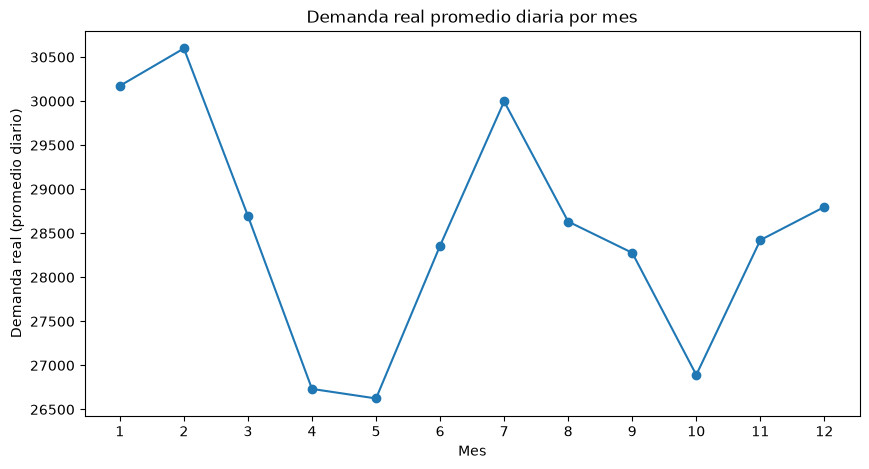

In [32]:
demanda_mes = demanda.groupby('mes')['value'].mean()

plt.figure(figsize=(10, 5))
plt.plot(demanda_mes.index, demanda_mes.values, marker='o')
plt.title('Demanda real promedio diaria por mes')
plt.xlabel('Mes')
plt.ylabel('Demanda real (promedio diario)')
plt.xticks(range(1, 13))
plt.show()

El mes con mayor promedio de demanda febrero con 30.598, el de menor promedio de demanda mayo con 26.625. Esto se puede deber a las estaciones, ya que otro mes con mucha demanda es julio y con poca demanda tambien es octubre. Los datos altos corresponden con las estaciones de invierno y verano, y los valores bajos con las estaciones de primavera y otoño. En el gráfico se ven dos picos (febrero y julio) y dos valles (abril-mayo y octubre)

### ¿Cuándo es más barata la electricidad?

In [33]:
precio = df_limpio[df_limpio['name'] == 'Precio mercado SPOT Diario ESP'].copy()
precio['mes'] = precio['datetime'].dt.month
precio_mes = precio.groupby('mes')['value'].mean()
print(precio_mes)

mes
1     49.014750
2     38.681203
3     36.186430
4     36.449878
5     43.064382
6     50.650967
7     51.760191
8     51.687586
9     54.956233
10    55.946721
11    55.057611
12    56.063097
Name: value, dtype: float64


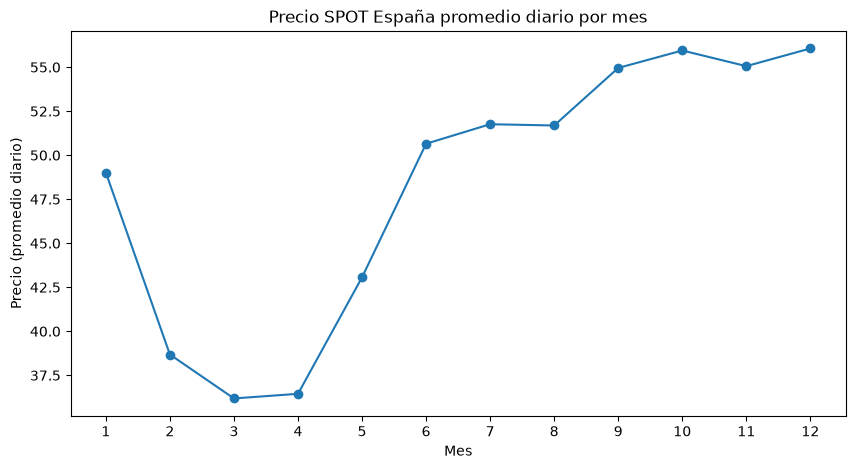

In [34]:
plt.figure(figsize=(10, 5))
plt.plot(precio_mes.index, precio_mes.values, marker='o')
plt.title('Precio SPOT España promedio diario por mes')
plt.xlabel('Mes')
plt.ylabel('Precio (promedio diario)')
plt.xticks(range(1, 13))
plt.show()

Los precios SPOT promedios más bajos son marzo con 36,2 y abril con 36,4, y los más altos son diciembre con 56,1 y octubre con 55,9. El patrón de meses más caros no coinciden en el patrón de demanda, febrero es el mes de mayor demanda pero es uno de los mas baratos y octubre tiene poca demanda y es de los más caros. Esto puede deberse a la disponibilidad de la energía en estas épocas, o tal vez algún año está subiendo los promedios por algún fenómeno. Son hipótesis que se revisan más adelante con las series de generación.

### ¿Qué fuente genera más y  energía?

In [35]:
generacion = df_limpio[df_limpio['name'].str.startswith('Generación programada PBF')]
generacion = generacion[generacion['name'] != 'Generación programada PBF total']
generacion.groupby('name')['value'].mean().sort_values(ascending=False)

name
Generación programada PBF Nuclear                     150840.289863
Generación programada PBF Eólica                      142036.368110
Generación programada PBF Carbón                       94283.964399
Generación programada PBF UGH + no UGH                 90268.082530
Generación programada PBF Gas Natural Cogeneración     68037.737185
Generación programada PBF Ciclo combinado              33292.798885
Generación programada PBF Solar fotovoltaica           21561.278368
Generación programada PBF Turbinación bombeo            9383.232566
Name: value, dtype: float64

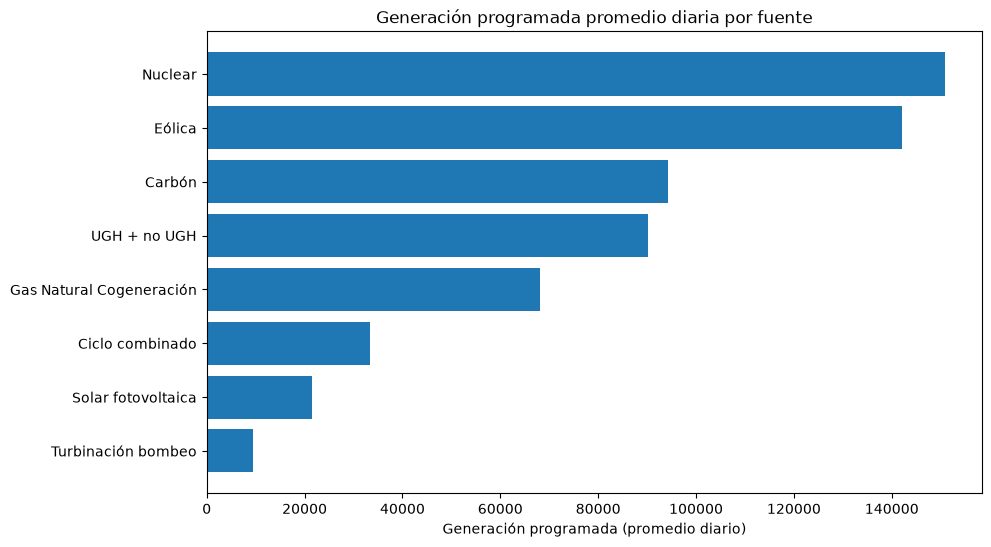

In [36]:
fuentes = generacion.groupby('name')['value'].mean().sort_values()
nombres = fuentes.index.str.replace('Generación programada PBF ', '')

plt.figure(figsize=(10, 6))
plt.barh(nombres, fuentes.values)
plt.title('Generación programada promedio diaria por fuente')
plt.xlabel('Generación programada (promedio diario)')
plt.show()

La fuente que mayor generación de energía programada tiene es la nuclear con 150.840 seguida muy de cerca por la eólica con 142.036, mientras que la que menos generación programada tiene es la turbinación bombeo con 9.383. En los datos no se contó con Generación programada PBF total​ ya que esta no es una fuente de energía, sino la suma de todas ellas.

## 4. Analisis complejo

### ¿Cómo cambió el precio a lo largo de los 5 años?

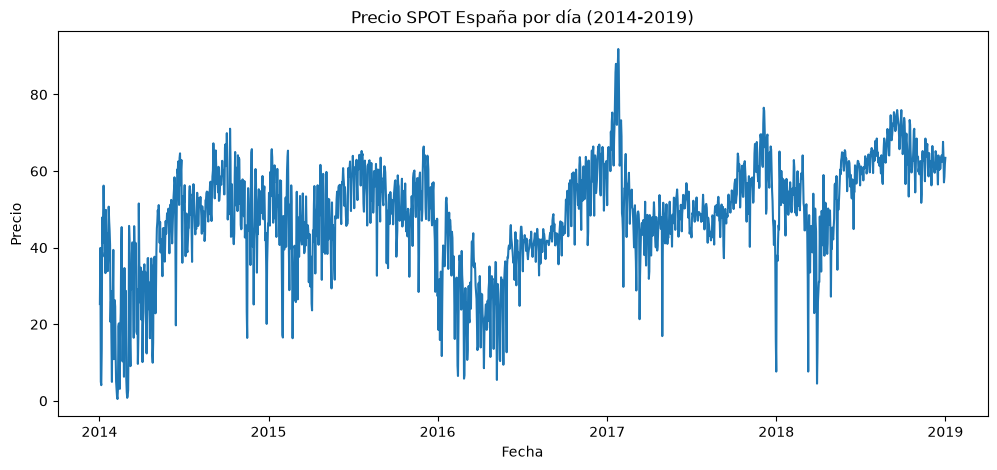

In [37]:
plt.figure(figsize=(12, 5))
plt.plot(precio['datetime'], precio['value'])
plt.title('Precio SPOT España por día (2014-2019)')
plt.xlabel('Fecha')
plt.ylabel('Precio')
plt.show()

Vemos que hay un pico muy alto a inicios del 2017 y uno muy bajo a principios del 2014. Se puede apreciar en los primeros meses de 2014 el precio llega a valores cercanos a 0, mientras que a fines de 2018 ronda 55-70. Al ser valores diarios la linea varia mucho y tiene mucho ruido.

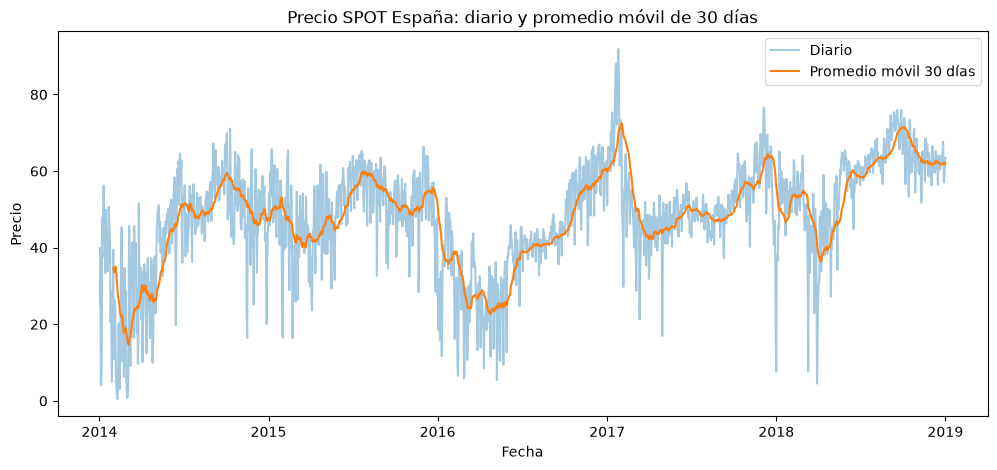

In [38]:
precio['media_30'] = precio['value'].rolling(30).mean()

plt.figure(figsize=(12, 5))
plt.plot(precio['datetime'], precio['value'], alpha=0.4, label='Diario')
plt.plot(precio['datetime'], precio['media_30'], label='Promedio móvil 30 días')
plt.title('Precio SPOT España: diario y promedio móvil de 30 días')
plt.xlabel('Fecha')
plt.ylabel('Precio')
plt.legend()
plt.show()